# Problem Set 2: Neural networks & optimisation

Analysis of Unstructured Data. Author: Rafał Głodek, Bartłomiej Mielcarz

Problems 1–3 are theory answers in Markdown. Problems 4–7 call the code in `src/` and discuss the results.

---

## Problem 1 : Softmax + Cross-Entropy

### **Setup**

We are given the logits $z\in\mathbb{R}^K$, the softmax probabilities

$$
p_k=\frac{e^{z_k}}{\sum_{j=1}^K e^{z_j}},
$$

and the cross-entropy loss

$$
L=-\sum_{k=1}^K y_k\log p_k,
$$

where $y$ is a one-hot encoded target, meaning

$$
y_k\in\{0,1\},\qquad \sum_{k=1}^K y_k=1.
$$

We want to prove that

$$
\boxed{\frac{\partial L}{\partial z_i}=p_i-y_i.}
$$

### **Step 1: substitute the softmax into the loss**

Taking the logarithm of $p_k$, we obtain

$$
\begin{aligned}
\log p_k
&=\log\left(\frac{e^{z_k}}{\sum_{j=1}^K e^{z_j}}\right)\\
&=z_k-\log\left(\sum_{j=1}^K e^{z_j}\right).
\end{aligned}
$$

Substituting into the cross-entropy loss,

$$
\begin{aligned}
L
&=-\sum_{k=1}^K y_k
\left(z_k-\log\left(\sum_{j=1}^K e^{z_j}\right)\right)\\[4pt]
&=-\sum_{k=1}^K y_kz_k
+\left(\sum_{k=1}^K y_k\right)
\log\left(\sum_{j=1}^K e^{z_j}\right).
\end{aligned}
$$

Since $\sum_{k=1}^K y_k=1$, we get

$$
\boxed{
L=-\sum_{k=1}^K y_kz_k+
\log\left(\sum_{j=1}^K e^{z_j}\right).
}
$$

### **Step 2: differentiate with respect to $z_i$**

Differentiating both terms separately,

$$
\frac{\partial L}{\partial z_i}
=
-\frac{\partial}{\partial z_i}
\left(\sum_{k=1}^K y_kz_k\right)
+
\frac{\partial}{\partial z_i}
\log\left(\sum_{j=1}^K e^{z_j}\right).
$$

For the first term,

$$
-\frac{\partial}{\partial z_i}
\left(\sum_{k=1}^K y_kz_k\right)=-y_i.
$$

For the second term, applying the chain rule,

$$
\begin{aligned}
\frac{\partial}{\partial z_i}
\log\left(\sum_{j=1}^K e^{z_j}\right)
&=\frac{1}{\sum_{j=1}^K e^{z_j}}
\frac{\partial}{\partial z_i}
\left(\sum_{j=1}^K e^{z_j}\right)\\[4pt]
&=\frac{e^{z_i}}{\sum_{j=1}^K e^{z_j}}\\[4pt]
&=p_i.
\end{aligned}
$$

Combining the two results,

$$
\boxed{\frac{\partial L}{\partial z_i}=p_i-y_i.}
$$

Equivalently, in vector notation,

$$
\boxed{\nabla_z L=p-y.}\qquad\blacksquare
$$

### **Step 3: why are softmax and cross-entropy paired?**

The key advantage is that **their combination produces an exceptionally simple gradient**.

Instead of explicitly computing the full softmax Jacobian, the gradient reduces to the difference between the predicted probabilities and the target distribution:

$$
\nabla_z L=p-y.
$$

This has several benefits:

1. **Simple computation:** The gradient requires only subtracting the target vector from the predicted probability vector.

2. **Clear interpretation:** For the correct class $i$, the gradient is $p_i-1$, encouraging its logit to increase. For incorrect classes, the gradient is $p_i$, encouraging their logits to decrease during gradient descent.

3. **Numerical stability:** The combined loss can be implemented using a stable log-sum-exp expression, avoiding explicitly computing $\log p_i$ for extremely small probabilities.

4. **Effective backpropagation:** The simplified gradient avoids an additional multiplicative softmax derivative that could make gradients unnecessarily small.

---

## Problem 2: Backpropagation in a Two-Layer MLP

We are given a two-layer neural network:

$$
h=\sigma(W_1x+b_1),
$$

$$
\hat y=\operatorname{softmax}(W_2h+b_2),
$$

with the cross-entropy loss

$$
L=-\sum_{k=1}^K y_k\log\hat y_k.
$$

Our goal is to derive

$$
\boxed{
\frac{\partial L}{\partial W_2},\quad
\frac{\partial L}{\partial b_2},\quad
\frac{\partial L}{\partial W_1},\quad
\frac{\partial L}{\partial b_1}.
}
$$

### **Step 1: define intermediate variables**

To simplify the notation, let

$$
\begin{aligned}
z_1 &= W_1x+b_1,\\
h &= \sigma(z_1),\\
z_2 &= W_2h+b_2,\\
\hat y &= \operatorname{softmax}(z_2).
\end{aligned}
$$

Assume the dimensions are

$$
\begin{aligned}
x&\in\mathbb R^d,\\
W_1&\in\mathbb R^{m\times d},\\
b_1&\in\mathbb R^m,\\
W_2&\in\mathbb R^{K\times m},\\
b_2&\in\mathbb R^K.
\end{aligned}
$$

The computational graph is

$$
x \longrightarrow z_1 \longrightarrow h
\longrightarrow z_2 \longrightarrow \hat y
\longrightarrow L.
$$

Backpropagation proceeds in the opposite direction.

### **Step 2: gradient with respect to the output layer**

From Problem 1, we already know that softmax combined with cross-entropy gives

$$
\boxed{\frac{\partial L}{\partial z_2}=\hat y-y.}
$$

Define the output error:

$$
\delta_2=\hat y-y.
$$

#### **2.1. Derivative with respect to $W_2$**

Recall that

$$
z_{2,k}=\sum_{j=1}^m W_{2,kj}h_j+b_{2,k}.
$$

Applying the chain rule,

$$
\frac{\partial L}{\partial W_{2,kj}}
=
\sum_{\ell=1}^K
\frac{\partial L}{\partial z_{2,\ell}}
\frac{\partial z_{2,\ell}}{\partial W_{2,kj}}.
$$

Since

$$
\frac{\partial z_{2,\ell}}{\partial W_{2,kj}}
=
\begin{cases}
h_j,&\ell=k,\\
0,&\ell\neq k,
\end{cases}
$$

we obtain

$$
\frac{\partial L}{\partial W_{2,kj}}
=(\hat y_k-y_k)h_j.
$$

Therefore, in matrix notation,

$$
\boxed{
\frac{\partial L}{\partial W_2}
=(\hat y-y)h^\top.
}
$$

#### **2.2. Derivative with respect to $b_2$**

Similarly,

$$
\frac{\partial L}{\partial b_{2,k}}
=
\sum_{\ell=1}^K
\frac{\partial L}{\partial z_{2,\ell}}
\frac{\partial z_{2,\ell}}{\partial b_{2,k}}.
$$

Because

$$
\frac{\partial z_{2,\ell}}{\partial b_{2,k}}
=
\begin{cases}
1,&\ell=k,\\
0,&\ell\neq k,
\end{cases}
$$

we get

$$
\boxed{
\frac{\partial L}{\partial b_2}
=\hat y-y.
}
$$

### **Step 3: backpropagate through the hidden layer**

We now calculate the gradient of $L$ with respect to $z_1$.

First, using the chain rule,

$$
\frac{\partial L}{\partial h_j}
=
\sum_{k=1}^K
\frac{\partial L}{\partial z_{2,k}}
\frac{\partial z_{2,k}}{\partial h_j}.
$$

Since

$$
z_{2,k}=\sum_{j=1}^m W_{2,kj}h_j+b_{2,k},
$$

we have

$$
\frac{\partial z_{2,k}}{\partial h_j}=W_{2,kj}.
$$

Thus,

$$
\frac{\partial L}{\partial h_j}
=
\sum_{k=1}^K(\hat y_k-y_k)W_{2,kj}.
$$

In vector notation,

$$
\boxed{
\frac{\partial L}{\partial h}
=W_2^\top(\hat y-y).
}
$$

Next, recall that

$$
h_j=\sigma(z_{1,j}).
$$

Because $\sigma$ acts elementwise,

$$
\frac{\partial h_j}{\partial z_{1,j}}
=\sigma'(z_{1,j}).
$$

Applying the chain rule once more,

$$
\frac{\partial L}{\partial z_{1,j}}
=
\frac{\partial L}{\partial h_j}
\sigma'(z_{1,j}).
$$

Therefore,

$$
\boxed{
\frac{\partial L}{\partial z_1}
=
\left(W_2^\top(\hat y-y)\right)
\odot\sigma'(z_1).
}
$$

Here, $\odot$ denotes elementwise multiplication (Hadamard product).

Define the hidden-layer error:

$$
\boxed{
\delta_1=
\left(W_2^\top\delta_2\right)\odot\sigma'(z_1).
}
$$

### **Step 4: gradient with respect to the first layer**

#### **4.1. Derivative with respect to $W_1$**

Recall that

$$
z_{1,j}=\sum_{i=1}^d W_{1,ji}x_i+b_{1,j}.
$$

By the chain rule,

$$
\frac{\partial L}{\partial W_{1,ji}}
=
\sum_{\ell=1}^m
\frac{\partial L}{\partial z_{1,\ell}}
\frac{\partial z_{1,\ell}}{\partial W_{1,ji}}.
$$

Since

$$
\frac{\partial z_{1,\ell}}{\partial W_{1,ji}}
=
\begin{cases}
x_i,&\ell=j,\\
0,&\ell\neq j,
\end{cases}
$$

we obtain

$$
\frac{\partial L}{\partial W_{1,ji}}
=\delta_{1,j}x_i.
$$

Therefore,

$$
\boxed{
\frac{\partial L}{\partial W_1}
=
\delta_1x^\top
=
\left[
W_2^\top(\hat y-y)\odot\sigma'(z_1)
\right]x^\top.
}
$$

#### **4.2. Derivative with respect to $b_1$**

Similarly,

$$
\frac{\partial L}{\partial b_{1,j}}
=
\frac{\partial L}{\partial z_{1,j}}
\frac{\partial z_{1,j}}{\partial b_{1,j}}.
$$

Since

$$
\frac{\partial z_{1,j}}{\partial b_{1,j}}=1,
$$

we obtain

$$
\boxed{
\frac{\partial L}{\partial b_1}
=
\delta_1
=
W_2^\top(\hat y-y)\odot\sigma'(z_1).
}
$$

### **Final result**

Let

$$
\delta_2=\hat y-y,
$$

$$
\delta_1=(W_2^\top\delta_2)\odot\sigma'(W_1x+b_1).
$$

Then all four gradients are:

**Output layer:**

$$
\boxed{
\frac{\partial L}{\partial W_2}=\delta_2h^\top
}
$$

$$
\boxed{
\frac{\partial L}{\partial b_2}=\delta_2
}
$$

**Hidden layer:**

$$
\boxed{
\frac{\partial L}{\partial W_1}=\delta_1x^\top
}
$$

$$
\boxed{
\frac{\partial L}{\partial b_1}=\delta_1
}
$$

These formulas hold for any differentiable elementwise activation function $\sigma$. At nondifferentiable points, such as zero for ReLU, a conventional subgradient may be used.


---
## Problem 3: SGD, Momentum and Adam

We want to:

1. Write the update rules for **SGD, SGD with momentum, and Adam**.
2. Show that momentum is an **exponential moving average (EMA)** of gradients.
3. Explain why Adam uses **bias correction** in its first few iterations.

### **Step 1: Stochastic Gradient Descent (SGD)**

Let $\theta\in\mathbb R^d$ denote the model parameters, and let $L(\theta)$ be the loss function.

At iteration $t$, we compute the stochastic gradient

$$
g_t=\nabla_\theta L_{\mathcal B_t}(\theta_{t-1}),
$$

where $\mathcal B_t$ denotes the sampled mini-batch.

The SGD update rule is

$$
\boxed{\theta_t=\theta_{t-1}-\eta g_t}
$$

where $\eta>0$ is the learning rate.

SGD moves the parameters in the direction opposite to the gradient. However, stochastic gradients can be noisy, causing oscillations during optimization.

### **Step 2: SGD with Momentum**

Momentum introduces an auxiliary variable $m_t$, which accumulates information from previous gradients.

Using the normalized momentum convention, the update rules are

$$
\boxed{
\begin{aligned}
m_t&=\beta m_{t-1}+(1-\beta)g_t,\\
\theta_t&=\theta_{t-1}-\eta m_t,
\end{aligned}
}
$$

where

- $\beta\in[0,1)$ is the momentum coefficient, typically $0.9$.
- $m_0=0$ is the initial momentum.
- $\eta$ is the learning rate.

#### **2.1. Show that momentum is an exponential moving average**

Starting with

$$
m_t=\beta m_{t-1}+(1-\beta)g_t,
$$

we recursively substitute earlier values.

For $t=1$,

$$
m_1=\beta m_0+(1-\beta)g_1.
$$

Since $m_0=0$,

$$
m_1=(1-\beta)g_1.
$$

For $t=2$,

$$
\begin{aligned}
m_2
&=\beta m_1+(1-\beta)g_2\\
&=\beta(1-\beta)g_1+(1-\beta)g_2.
\end{aligned}
$$

For $t=3$,

$$
\begin{aligned}
m_3
&=\beta m_2+(1-\beta)g_3\\
&=\beta^2(1-\beta)g_1
+\beta(1-\beta)g_2
+(1-\beta)g_3.
\end{aligned}
$$

Continuing this process gives

$$
\boxed{
m_t=(1-\beta)\sum_{i=1}^{t}\beta^{t-i}g_i.
}
$$

Thus, momentum is an **exponentially weighted sum of past gradients**.


### **Step 3: Adam (Adaptive Moment Estimation)**

Adam combines momentum with adaptive learning rates.

It maintains two moving averages:

- $m_t$: exponential moving average of gradients (first moment).
- $v_t$: exponential moving average of squared gradients (second raw moment).

The update rules are:

**1. Compute the gradient**

$$
g_t=\nabla_\theta L_{\mathcal B_t}(\theta_{t-1}).
$$

**2. Update the first moment**

$$
\boxed{
m_t=\beta_1m_{t-1}+(1-\beta_1)g_t
}
$$

**3. Update the second moment**

$$
\boxed{
v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2
}
$$

where $g_t^2$ denotes elementwise squaring.

**4. Apply bias correction**

$$
\boxed{
\hat m_t=\frac{m_t}{1-\beta_1^t}
}
$$

$$
\boxed{
\hat v_t=\frac{v_t}{1-\beta_2^t}
}
$$

**5. Update the parameters**

$$
\boxed{
\theta_t=
\theta_{t-1}
-\eta\frac{\hat m_t}{\sqrt{\hat v_t}+\varepsilon}
}
$$

All operations involving vectors in the final update are performed elementwise.

Typical hyperparameters are

$$
\beta_1=0.9,\qquad
\beta_2=0.999,\qquad
\varepsilon=10^{-8}.
$$

We initialize $m_0=v_0=0$.

### **Step 4: why does Adam need bias correction?**

Both moving averages start at zero. Consequently, during the first few iterations, their values are systematically biased toward zero.

Consider the first moment:

$$
m_t=\beta_1m_{t-1}+(1-\beta_1)g_t.
$$

From Step 2, we know that

$$
m_t=(1-\beta_1)\sum_{i=1}^t\beta_1^{t-i}g_i.
$$

Assume that the gradients have a constant expected value

$$
\mathbb E[g_i]=\mu.
$$

Taking expectations,

$$
\begin{aligned}
\mathbb E[m_t]
&=(1-\beta_1)
\sum_{i=1}^t\beta_1^{t-i}\mathbb E[g_i]\\
&=(1-\beta_1)\mu
\sum_{i=1}^t\beta_1^{t-i}.
\end{aligned}
$$

Using the geometric series formula,

$$
\sum_{i=1}^t\beta_1^{t-i}
=\frac{1-\beta_1^t}{1-\beta_1},
$$

we obtain

$$
\boxed{
\mathbb E[m_t]=(1-\beta_1^t)\mu.
}
$$

Since $1-\beta_1^t<1$, the estimate is biased toward zero.

To correct this, Adam defines

$$
\hat m_t=\frac{m_t}{1-\beta_1^t}.
$$

Therefore,

$$
\begin{aligned}
\mathbb E[\hat m_t]
&=\frac{\mathbb E[m_t]}{1-\beta_1^t}\\
&=\frac{(1-\beta_1^t)\mu}{1-\beta_1^t}\\
&=\mu.
\end{aligned}
$$

Hence,

$$
\boxed{\mathbb E[\hat m_t]=\mu.}
$$

Under the constant-moment assumption, the bias-corrected first moment is unbiased.

The same argument applies to the second moment. If

$$
\mathbb E[g_i^2]=\nu,
$$

then

$$
\mathbb E[v_t]=(1-\beta_2^t)\nu.
$$

Consequently,

$$
\boxed{
\hat v_t=\frac{v_t}{1-\beta_2^t}
}
$$

removes this initialization bias.

#### **4.1. Example: the first iteration**

Consider Adam with

$$
\beta_1=0.9,\qquad \beta_2=0.999.
$$

At $t=1$, since $m_0=v_0=0$,

$$
m_1=0.1g_1
$$

and

$$
v_1=0.001g_1^2.
$$

Both estimates are much smaller than the gradient quantities they are intended to estimate.

After bias correction,

$$
\begin{aligned}
\hat m_1
&=\frac{0.1g_1}{1-0.9}\\
&=g_1,
\end{aligned}
$$

and

$$
\begin{aligned}
\hat v_1
&=\frac{0.001g_1^2}{1-0.999}\\
&=g_1^2.
\end{aligned}
$$

Thus,

$$
\boxed{
\hat m_1=g_1,\qquad \hat v_1=g_1^2.
}
$$

Bias correction prevents the initial zero values from artificially shrinking the moment estimates. This is particularly important for the second moment, since $\beta_2$ is typically very close to 1.

As $t\to\infty$,

$$
\beta_1^t\to0,\qquad \beta_2^t\to0,
$$

so

$$
\hat m_t\approx m_t,\qquad
\hat v_t\approx v_t.
$$

Therefore, bias correction matters most during the first few iterations.

## Problem 4: Two-layer MLP in NumPy with a gradient check

**Approach and assumptions:**

- **Data:** the Problem-Set-1 digits (1797 images, 64 pixels, 10 classes), pixels divided by 16 so they lie in $[0, 1]$. A stratified 60/20/20 train/validation/test split (1077/360/360, seed 0) is shared by Problems 4–7.
- **Network:** exactly Problem 2. Samples are rows, so the code computes $Z_1 = X W_1^\top + b_1$. The loss is the batch mean, so $\delta_2 = (\hat y - y)/B$.
- **Initialisation:** $W \sim \mathcal{N}(0, s^2/\text{fan-in})$ with $s^2 = 2$ for ReLU and 1 otherwise; biases start at 0.
- **Gradient check:** central differences with $\varepsilon = 10^{-5}$ for every entry of $W_1, b_1, W_2, b_2$, in `float64`, on 32 images with $m = 32$ hidden units. Problem 2 holds for any $\sigma$, so we test ReLU, tanh and sigmoid.
- **Pass criterion:** relative error $\frac{\|a - n\|}{\|a\| + \|n\|} < 10^{-5}$, both per tensor and per entry ($a$ = analytic, $n$ = numerical; entries where both are exactly 0 are skipped).

In [1]:
import numpy as np

from src.data import load_digits_features, make_splits, one_hot
from src.mlp_numpy import gradient_check

X, y = load_digits_features()
splits = make_splits(X, y, random_state=0)
print(f"X: shape {X.shape}, dtype {X.dtype}, range [{X.min():.0f}, {X.max():.0f}]")
print(f"train / val / test: {len(splits.y_train)} / {len(splits.y_val)} / {len(splits.y_test)}")

X: shape (1797, 64), dtype float64, range [0, 1]
train / val / test: 1077 / 360 / 360


In [2]:
X_batch, Y_batch = splits.X_train[:32], one_hot(splits.y_train[:32])

check = gradient_check(X_batch, Y_batch, n_hidden=32, random_state=0)
assert check["passes"].all(), check[~check["passes"]]
check

,activation,parameter,shape,entries,grad norm,relative error,max entrywise rel. error,passes
0,relu,W1,"(32, 64)",2048,0.453374,5.610466e-10,2.094597e-06,True
1,relu,b1,"(32,)",32,0.105958,3.415325e-10,7.616346e-09,True
2,relu,W2,"(10, 32)",320,0.381185,2.841720e-10,4.526447e-07,True
3,relu,b2,"(10,)",10,0.128826,2.119475e-10,7.703085e-10,True
4,tanh,W1,"(32, 64)",2048,0.626115,4.670567e-10,8.338613e-07,True
5,tanh,b1,"(32,)",32,0.137177,3.643851e-10,2.080165e-08,True
6,tanh,W2,"(10, 32)",320,0.451324,2.957884e-10,1.001509e-07,True
7,tanh,b2,"(10,)",10,0.189039,1.435870e-10,2.804280e-10,True
8,sigmoid,W1,"(32, 64)",2048,0.155720,1.865466e-09,3.331963e-06,True
9,sigmoid,b1,"(32,)",32,0.030518,1.478376e-09,1.854461e-08,True


In [3]:
# Effect of the finite-difference step: too large -> truncation error O(eps^2), too small -> rounding error O(1e-16 / eps).
for eps in (1e-3, 1e-4, 1e-5, 1e-6, 1e-7):
    worst = gradient_check(X_batch, Y_batch, n_hidden=32, activations=("tanh",), eps=eps)["relative error"].max()
    print(f"eps = {eps:.0e}: worst relative error {worst:.1e}")

eps = 1e-03: worst relative error 1.7e-07
eps = 1e-04: worst relative error 1.7e-09
eps = 1e-05: worst relative error 4.7e-10
eps = 1e-06: worst relative error 4.6e-09
eps = 1e-07: worst relative error 4.3e-08


**Interpretation**

- **All 12 tensors pass.** Relative errors are between $10^{-10}$ and $2 \cdot 10^{-9}$; the worst single entry is $2.5 \cdot 10^{-6}$ (sigmoid, $W_1$). The formulas of Problem 2 are correct for all three activations.
- **The step size matters.** The sweep is U-shaped: $\varepsilon = 10^{-3}$ gives truncation error ($1.7 \cdot 10^{-7}$), $\varepsilon = 10^{-7}$ gives rounding error ($4.7 \cdot 10^{-8}$), and $10^{-5}$ is the sweet spot ($4.5 \cdot 10^{-10}$).
- **ReLU's kink at 0** could break finite differences. Its worst entry is $1.1 \cdot 10^{-6}$, so no perturbation crossed it.

## Problem 5: The same network in PyTorch

**Approach and assumptions:**

- **Same model:** `Linear → ReLU → Linear` with `F.cross_entropy` ($m = 64$), initialised with the exact NumPy weights (seed 0).
- **Same training:** plain SGD (Problem 3) with $\eta = 0.1$, batch size 32 and 50 epochs, and both networks read the same precomputed batch order.
- **`float64` everywhere**, so only rounding can differ.
- **What we compare:** the gradients at initialisation and the loss at all 1700 steps. They agree if the difference is below $10^{-10}$.

In [4]:
import matplotlib.pyplot as plt

from src.data import epoch_batches
from src.mlp_numpy import NumpyMLP, train_numpy
from src.mlp_torch import TorchMLP, compare_gradients, compare_logs, final_weight_difference, train_torch
from src.plotting import plot_numpy_vs_torch

# splits comes from Problem 4.
model_np = NumpyMLP(n_inputs=64, n_hidden=64, n_classes=10, activation="relu", random_state=0)
model_torch = TorchMLP.from_numpy(model_np)

grads = compare_gradients(model_np, splits.X_train[:64], splits.y_train[:64])
assert grads["passes"].all(), grads[~grads["passes"]]
grads

,parameter,shape,max |autograd - numpy|,passes
0,W1,"(64, 64)",1.040834e-17,True
1,b1,"(64,)",1.387779e-17,True
2,W2,"(10, 64)",2.775558e-17,True
3,b2,"(10,)",2.775558e-17,True


In [5]:
schedule = epoch_batches(len(splits.y_train), batch_size=32, n_epochs=50, random_state=0)
log_np = train_numpy(model_np, splits.X_train, splits.y_train, schedule, lr=0.1)
log_torch = train_torch(model_torch, splits.X_train, splits.y_train, schedule, lr=0.1)

curves = compare_logs(log_np, log_torch)
assert curves["passes"].all(), curves[~curves["passes"]]
curves

,curve,points,max |numpy - torch|,max relative diff,final loss numpy,final loss torch,passes
0,step loss,1700,4.440892e-16,5.133572e-15,0.017017,0.017017,True
1,epoch loss,51,4.440892e-16,5.764298e-16,0.044997,0.044997,True


In [6]:
import torch

with torch.no_grad():
    pred_torch = model_torch(torch.from_numpy(splits.X_val)).argmax(dim=1).numpy()
pred_np = model_np.predict(splits.X_val)
print(f"largest weight difference after training: {final_weight_difference(model_np, model_torch):.1e}")
print(f"validation accuracy: NumPy {np.mean(pred_np == splits.y_val):.4f}, PyTorch {np.mean(pred_torch == splits.y_val):.4f}, "
      f"identical predictions: {np.array_equal(pred_np, pred_torch)}")

largest weight difference after training: 1.8e-15
validation accuracy: NumPy 0.9639, PyTorch 0.9639, identical predictions: True


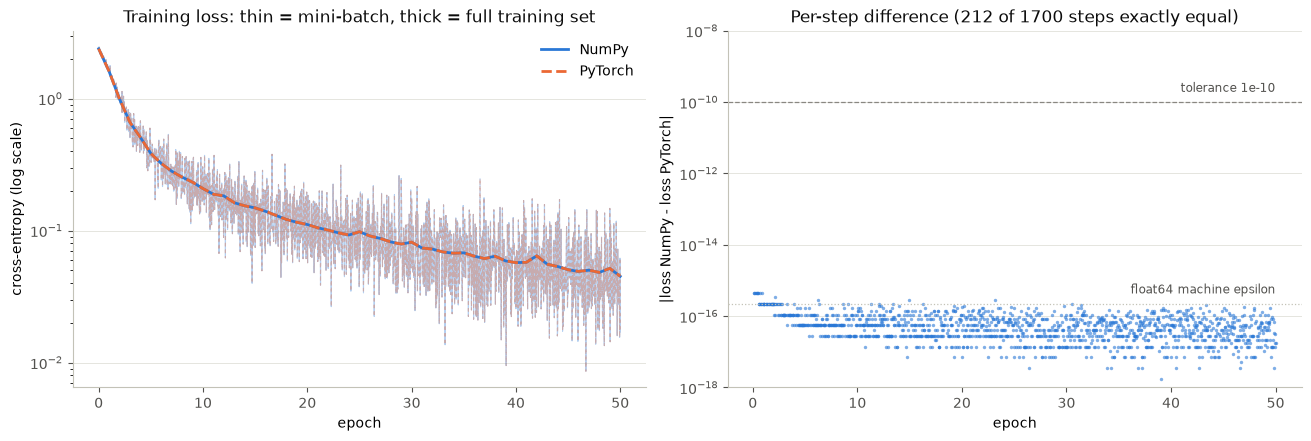

In [7]:
fig = plot_numpy_vs_torch(log_np, log_torch, steps_per_epoch=len(schedule[0]))
plt.show()

**Interpretation**

The two implementations agree to machine precision:

- gradients differ by at most $4.2 \cdot 10^{-17}$;
- losses over 1700 steps differ by at most $4.4 \cdot 10^{-16}$ (244 steps are bit-identical), and both end at 0.044997;
- trained weights differ by $2.2 \cdot 10^{-15}$, and the validation predictions are identical (accuracy 0.9639).

The differences do not grow during training (right panel). This is a second, independent confirmation of the NumPy backward pass.

## Problem 6: Regularisation

**Approach and assumptions:**

- **Model:** the MLP of Problem 5 with 256 ReLU units (about 19k parameters for 1077 images, so it can overfit). Adam (Problem 3, $\eta = 10^{-3}$), batch 32, up to 150 epochs.
- **L2:** add $\frac{\lambda}{2}\left(\|W_1\|^2 + \|W_2\|^2\right)$ to the loss (weights only, not biases).
- **Dropout:** each hidden unit is zeroed with probability $p$ during training.
- **Early stopping:** stop after 20 epochs without a lower validation loss and keep the best weights.
- **Tuning:** $\lambda$ and $p$ are picked by the lowest validation loss in a small sweep (seeds 0 and 1).
- **Runs:** no regularisation, each regulariser alone, and all three together, each with seeds 0, 1 and 2. The test set is only used for the final table.
- **Curves** are measured in evaluation mode (no dropout, no L2 term), so they are comparable. Each run uses one CPU thread for reproducibility; everything takes about 3 minutes.

In [8]:
import time

import matplotlib.pyplot as plt

from src.plotting import plot_learning_curves, plot_val_loss_comparison
from src.regularisation import (
    accuracy_table,
    best_strength,
    default_configs,
    run_study,
    strength_sweep,
    train_run,
)

# splits comes from Problem 4.
start = time.perf_counter()
sweep = strength_sweep(splits, l2_values=(1e-4, 1e-3, 1e-2, 1e-1), dropout_values=(0.2, 0.5, 0.8), seeds=(0, 1))
print(f"sweep: {time.perf_counter() - start:.0f} s")
sweep.round(4)

sweep: 20 s


,regulariser,strength,train acc,val acc,train loss,val loss,acc gap (train - val)
0,none,0.0000,1.0000,0.9681,0.0008,0.1542,0.0319
1,L2,0.0001,1.0000,0.9708,0.0034,0.1158,0.0292
2,L2,0.0010,0.9995,0.9736,0.0257,0.1064,0.0259
3,L2,0.0100,0.9791,0.9556,0.1878,0.2308,0.0236
4,L2,0.1000,0.8045,0.8000,1.2550,1.2783,0.0045
5,dropout,0.2000,1.0000,0.9778,0.0012,0.1243,0.0222
6,dropout,0.5000,1.0000,0.9764,0.0016,0.1184,0.0236
7,dropout,0.8000,0.9995,0.9750,0.0074,0.1104,0.0245


In [9]:
l2, p_drop = best_strength(sweep, "L2"), best_strength(sweep, "dropout")
print(f"chosen on validation loss: lambda = {l2:g}, dropout p = {p_drop:g}")

configs = default_configs(l2=l2, dropout=p_drop, patience=20)
start = time.perf_counter()
study = run_study(configs, splits, seeds=(0, 1, 2))
print(f"study: {len(configs)} configurations x 3 seeds in {time.perf_counter() - start:.0f} s")

# Same seed, same configuration -> identical history.
assert train_run(configs[0], splits, seed=0).history.equals(study["none"][0].history)

chosen on validation loss: lambda = 0.001, dropout p = 0.8
study: 5 configurations x 3 seeds in 16 s


In [10]:
accuracies = accuracy_table(study)
accuracies.round(4)

,configuration,train acc,train acc std,val acc,val acc std,test acc,test acc std,val loss,kept epoch
0,none,1.0000,0.0000,0.9685,0.0013,0.9741,0.0013,0.1527,150.0
1,L2,0.9997,0.0004,0.9731,0.0013,0.9731,0.0013,0.1078,150.0
2,dropout,0.9994,0.0004,0.9759,0.0026,0.9731,0.0035,0.1111,150.0
3,early stopping,0.9978,0.0004,0.9750,0.0000,0.9676,0.0052,0.1130,37.0
4,L2 + dropout + early stopping,0.9981,0.0000,0.9759,0.0013,0.9713,0.0035,0.1009,135.0


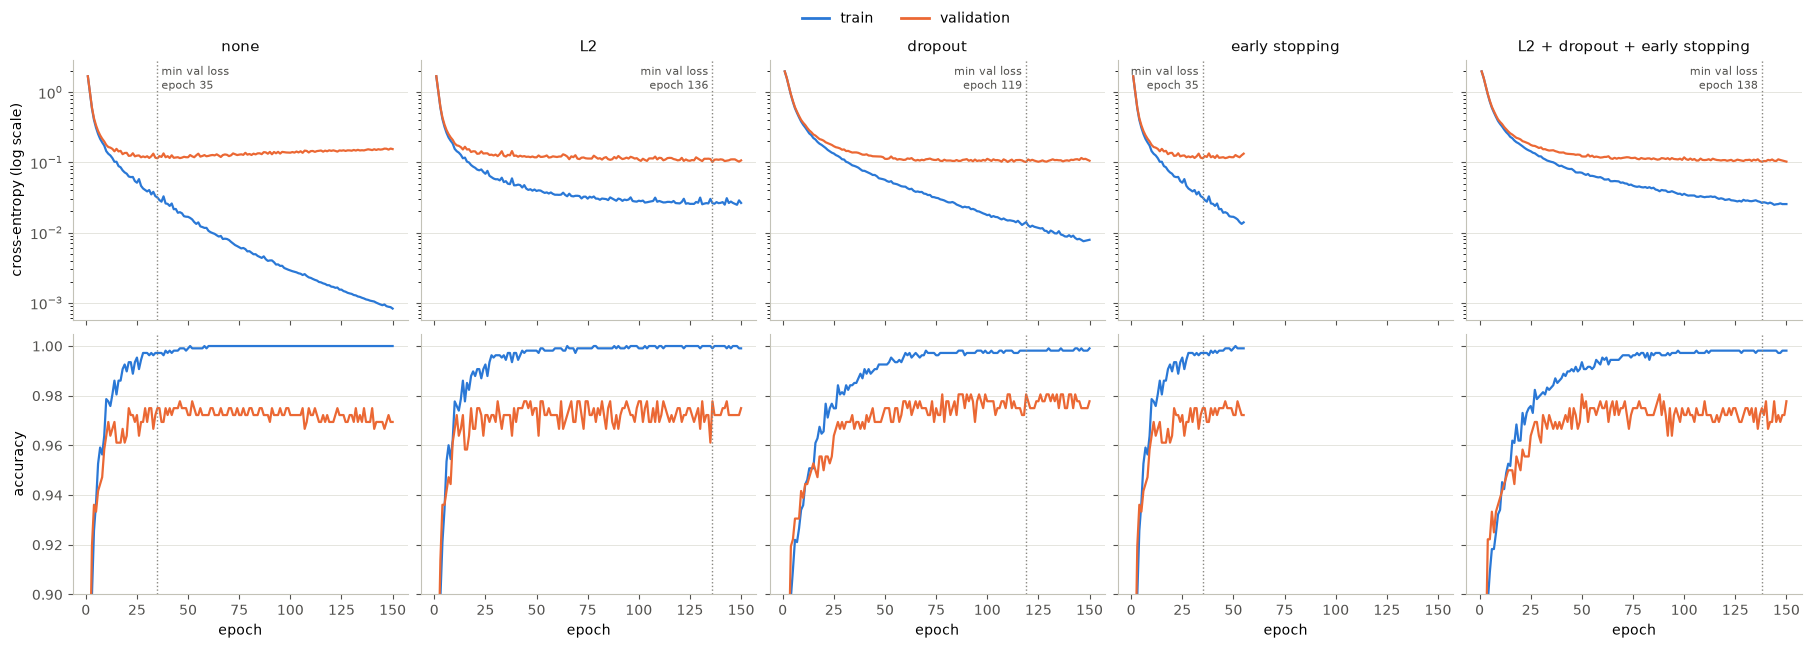

In [11]:
fig = plot_learning_curves(study, seed_index=0)
plt.show()

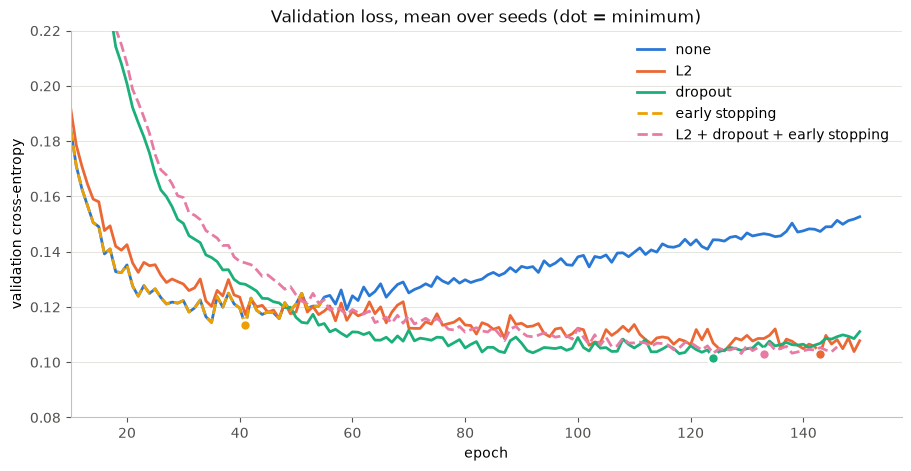

In [12]:
fig = plot_val_loss_comparison(study)
plt.show()

**Observations**

- **Chosen strengths:** $\lambda = 10^{-3}$ and $p = 0.8$. Too much L2 hurts quickly: $\lambda = 10^{-2}$ is already worse than no regularisation, and $\lambda = 10^{-1}$ drops training accuracy to 0.80.
- **Accuracy barely changes:** every setup lands between 0.968 and 0.976 on validation and test, a spread of 1–2 images out of 360, about the size of the seed noise.
- **Validation loss does change:** 0.153 without regularisation, 0.108 with L2, 0.111 with dropout, 0.113 with early stopping and 0.101 with all three.
- **Curves:** without regularisation the training loss keeps falling below $10^{-3}$, while the validation loss bottoms out at epoch 35 and then rises. L2 and dropout flatten the curves and push the minimum to epochs 136 and 119.

## Problem 7: Over- and under-fitting

**Evidence:** the curves and tables from Problem 6, plus the table below (means over 3 seeds). In each run, the epoch with the lowest validation loss separates **under-fitting** (before it, more training still helps) from **over-fitting** (after it, the validation loss rises while the training loss keeps falling).

In [13]:
from src.regularisation import fitting_diagnostics

# study, sweep and accuracies come from Problem 6.
fitting_diagnostics(study).round(4)

,configuration,epochs trained,min val loss epoch,min val loss,last val loss,rise after min,last train loss,last acc gap (train - val)
0,none,150.0000,37.0000,0.1130,0.1527,0.0397,0.0008,0.0315
1,L2,150.0000,136.3333,0.1002,0.1078,0.0076,0.0260,0.0265
2,dropout,150.0000,115.6667,0.0995,0.1111,0.0116,0.0074,0.0235
3,early stopping,57.0000,37.0000,0.1130,0.1237,0.0107,0.0125,0.0253
4,L2 + dropout + early stopping,148.6667,135.0000,0.1009,0.1046,0.0037,0.0248,0.0272


### Discussion

**Short answer.** The model under-fits in the early epochs and when regularisation is too strong. Without regularisation it over-fits after about epoch 37. L2 helped most.

**Under-fitting**

- **Early epochs:** both losses are still falling, so stopping here would waste accuracy.
- **Too much L2:** $\lambda = 0.1$ gives 0.80 accuracy on both train and validation. A low training score with a small gap means the model is too constrained.
- **Dropout** never under-fits in our range: even at $p = 0.8$ training accuracy is 0.9995.

**Over-fitting**

- Without regularisation, after epoch 37 the training loss falls to 0.0008 while the validation loss rises by 35% (0.113 → 0.153).
- Validation accuracy stays at about 0.97, so the model is not making more mistakes; it is becoming **over-confident**. By Problem 1 the gradient $p - y$ is never exactly 0, so training keeps pushing the logits apart. The few wrong validation predictions then become very confident and cost a lot of loss.

**Which regulariser helped most**

| | final val loss | rise after minimum | why |
|---|---|---|---|
| none | 0.153 | 0.040 | logits grow without limit |
| L2 | 0.108 | 0.008 | the $\lambda W$ term stops the weights (and logits) from growing |
| dropout | 0.111 | 0.012 | units cannot co-adapt, but the weights are not bounded |
| early stopping | 0.113 | 0.011 | only picks a point on the unregularised curve, so it cannot beat its minimum (0.113) |
| all three | 0.101 | 0.004 | best overall |

**L2 wins among single regularisers** because it targets the exact cause, the growing logits. It does need tuning: ten times too much ($\lambda = 10^{-2}$) already hurts.

**Why accuracy doesn't show it:** digits is an easy dataset, and with 360 test images one image is 0.28 points, so the 0.65-point spread is noise. Regularisation changes how confident the model is, not which class it picks.